# 34. RG3 미성형 — 공정 데이터에 신호 자체가 있는가 (상한 점검)

모델을 더 바꿔 보기 전에, **변수 ~140개 중 어느 하나라도 RG3 미성형을 정상과 가르는지** 확인.

- 같은 Run 안에서 라벨을 섞는 순열 검정 2,000번 → 변수를 많이 본 것까지 보정한 p(FWER)
- 비교군: ① 시간 맞춘 정상(같은 Run, ±10샷) ② 평가 대상 정상 전체
- 시차 스캔(−5~+5샷): 라벨과 공정 기록 시각이 어긋났을 가능성
- 양성 대조: 같은 방법으로 RG3 가스 (신호가 나와야 정상)

**해석**: 보정 p<0.05인 변수가 없으면 → RG3 미성형은 공유 공정값으로 관측 불가 (모델 문제가 아니라 데이터 한계)

In [1]:
import pandas as pd
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 250); pd.set_option('display.max_colwidth', 60)
from plot_style import set_style; set_style()
import rg3_short_scan as Q
R = Q.run('rg3')

[rg3] 샷 629 | 평가 대상 유형: {'정상': 595, '가스': 22, '미성형': 10} | 변수 147개
  스캔 완료: 미성형 vs matched
  스캔 완료: 미성형 vs all
  스캔 완료: 가스 vs matched
  스캔 완료: 가스 vs all


## 1. 미성형 샷 프로필 — 어디서, 어떤 상황에서 나왔나

In [2]:
display(R['profile'])
print('가스 샷 프로필 (비교용)'); display(R['profile_gas'])

,TimeStamp,run_id,Reason,불량 캐비티,Run 안 순서,Run 샷 수,재가동 후 샷,직전 간격(초),앞뒤 ±3샷 판정,평가 대상
0,2020-10-22 01:09:23,rg3_R2,미성형,RH,45,103,45,62.0,· · · [S] · · ·,True
1,2020-10-22 04:48:39,rg3_R3,미성형,RH,9,197,9,61.0,· G · [S] · · G,True
2,2020-10-22 05:42:13,rg3_R3,미성형,RH,60,197,60,63.0,· · · [S] · G ·,True
3,2020-10-22 06:12:03,rg3_R3,미성형,RH,88,197,88,63.0,· · · [S] · · ·,True
4,2020-10-22 06:58:22,rg3_R3,미성형,RH,132,197,132,61.0,· · · [S] · · ·,True
5,2020-10-23 02:25:54,rg3_R4,미성형,RH,65,74,37,60.0,· · · [S] · · ·,True
6,2020-10-23 05:47:40,rg3_R5,미성형,RH,62,176,62,61.0,· · · [S] · · ·,True
7,2020-10-23 05:54:52,rg3_R5,미성형,RH,69,176,69,60.0,· · · [S] · · G,True
8,2020-11-04 05:19:50,rg3_R6,미성형,NaN,16,36,16,62.0,· G G [S] S G ·,True
9,2020-11-04 05:20:51,rg3_R6,미성형,NaN,17,36,17,61.0,G G S [S] G · ·,True


가스 샷 프로필 (비교용)


,TimeStamp,run_id,Reason,불량 캐비티,Run 안 순서,Run 샷 수,재가동 후 샷,직전 간격(초),앞뒤 ±3샷 판정,평가 대상
0,2020-10-22 00:51:52,rg3_R2,가스,RH,28,103,28,60.0,· · · [G] · · ·,True
1,2020-10-22 01:04:15,rg3_R2,가스,RH,40,103,40,62.0,· · · [G] · · ·,True
2,2020-10-22 01:26:54,rg3_R2,가스,RH,62,103,62,63.0,· · · [G] · · ·,True
3,2020-10-22 01:57:47,rg3_R2,가스,RH,82,103,18,63.0,· · · [G] · · ·,True
4,2020-10-22 04:46:36,rg3_R3,가스,RH,7,197,7,63.0,· · · [G] · S ·,True
5,2020-10-22 04:51:46,rg3_R3,가스,RH,12,197,12,63.0,S · · [G] · · ·,True
6,2020-10-22 04:57:56,rg3_R3,가스,RH,18,197,18,62.0,· · · [G] · · ·,True
7,2020-10-22 05:10:17,rg3_R3,가스,RH,30,197,30,62.0,· · · [G] · · ·,True
8,2020-10-22 05:44:15,rg3_R3,가스,RH,62,197,62,62.0,· S · [G] · · ·,True
9,2020-10-22 07:37:31,rg3_R3,가스,RH,167,197,167,63.0,· · · [G] · · ·,True


## 2. 한눈 요약 — 최고 변수가 우연 수준을 넘는가

,대상,비교군,미성형 샷,정상 샷,변수 수,무작위 최대 |δ| 95% 지점,관측 최대 |δ|,보정 p<0.05 변수 수,가스 샷
0,미성형,matched,10.0,152,147,0.597,0.449,0,NaN
1,미성형,all,10.0,595,147,0.597,0.485,0,NaN
2,가스,matched,NaN,280,147,0.425,0.384,0,22.0
3,가스,all,NaN,595,147,0.436,0.454,1,22.0


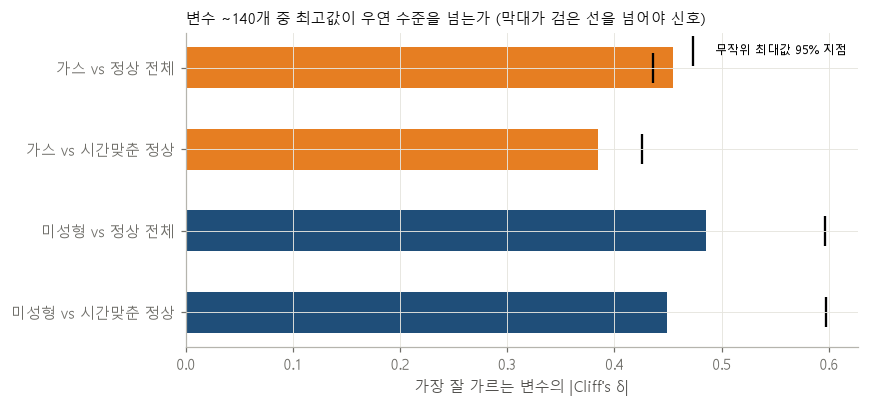

In [3]:
display(R['meta'].round(3))
Q.plot_null(R, save='./outputs/rg3_short_scan/null.png')

## 3. 변수 순위 (미성형 vs 시간 맞춘 정상 / 정상 전체)

In [4]:
cols = ['변수', '변환', 'AUC', "Cliff's δ", '방향', '순열 p', '보정 p(FWER)', '결측 비율']
print('===== 미성형 vs 시간 맞춘 정상 =====');  display(R['scan_미성형_matched'][cols].head(20).round(3))
print('===== 미성형 vs 정상 전체 =====');      display(R['scan_미성형_all'][cols].head(20).round(3))

===== 미성형 vs 시간 맞춘 정상 =====


,변수,변환,AUC,Cliff's δ,방향,순열 p,보정 p(FWER),결측 비율
0,Barrel_Temperature_4,다음샷변화(미래),0.724,0.449,미성형에서 ↑,0.015,0.604,0.006
1,Hopper_Temperature,직전변화,0.288,-0.424,미성형에서 ↓,0.026,0.744,0.006
2,Plasticizing_Time,편차20,0.706,0.411,미성형에서 ↑,0.026,0.798,0.031
3,Barrel_Temperature_5,직전10샷std,0.691,0.383,미성형에서 ↑,0.044,0.909,0.012
4,Plasticizing_Time,Run중앙값대비(미래포함),0.680,0.359,미성형에서 ↑,0.052,0.960,0.000
5,Plasticizing_Position,직전변화,0.676,0.353,미성형에서 ↑,0.061,0.974,0.006
6,Plasticizing_Time,직전변화,0.651,0.302,미성형에서 ↑,0.106,1.000,0.006
7,Hopper_Temperature,직전10샷std,0.354,-0.292,미성형에서 ↓,0.094,1.000,0.012
8,Cycle_Time,직전10샷std,0.646,0.292,미성형에서 ↑,0.095,1.000,0.012
9,Plasticizing_Time,다음샷변화(미래),0.358,-0.284,미성형에서 ↓,0.114,1.000,0.006


===== 미성형 vs 정상 전체 =====


,변수,변환,AUC,Cliff's δ,방향,순열 p,보정 p(FWER),결측 비율
0,Barrel_Temperature_5,직전10샷std,0.743,0.485,미성형에서 ↑,0.009,0.398,0.020
1,Plasticizing_Time,Run중앙값대비(미래포함),0.741,0.482,미성형에서 ↑,0.006,0.418,0.000
2,Plasticizing_Time,편차20,0.741,0.481,미성형에서 ↑,0.009,0.427,0.048
3,Barrel_Temperature_4,다음샷변화(미래),0.731,0.463,미성형에서 ↑,0.011,0.538,0.010
4,Cushion_Position,직전10샷std,0.729,0.458,미성형에서 ↑,0.015,0.565,0.020
5,Hopper_Temperature,직전10샷std,0.273,-0.455,미성형에서 ↓,0.010,0.580,0.020
6,Plasticizing_Position,직전변화,0.684,0.368,미성형에서 ↑,0.047,0.968,0.010
7,Hopper_Temperature,직전변화,0.320,-0.361,미성형에서 ↓,0.048,0.977,0.010
8,Plasticizing_Time,수준,0.680,0.361,미성형에서 ↑,0.021,0.978,0.000
9,Cycle_Time,직전10샷std,0.660,0.321,미성형에서 ↑,0.057,0.998,0.020


In [5]:
# 양성 대조: 가스
print('===== 가스 vs 시간 맞춘 정상 =====');  display(R['scan_가스_matched'][cols].head(15).round(3))
print('===== 가스 vs 정상 전체 =====');      display(R['scan_가스_all'][cols].head(15).round(3))

===== 가스 vs 시간 맞춘 정상 =====


,변수,변환,AUC,Cliff's δ,방향,순열 p,보정 p(FWER),결측 비율
0,Cushion_Position,직전10샷std,0.692,0.384,가스에서 ↑,0.007,0.168,0.013
1,Mold_Temperature_3,직전변화,0.628,0.256,가스에서 ↑,0.038,0.960,0.007
2,Injection_Time,직전10샷std,0.622,0.244,가스에서 ↑,0.022,0.984,0.013
3,Plasticizing_Time,직전10샷std,0.378,-0.244,가스에서 ↓,0.062,0.984,0.013
4,Mold_Temperature_3,편차20,0.613,0.226,가스에서 ↑,0.054,0.998,0.040
5,Cycle_Time,Run중앙값대비(미래포함),0.611,0.222,가스에서 ↑,0.043,0.998,0.000
6,Cycle_Time,수준,0.611,0.222,가스에서 ↑,0.043,0.998,0.000
7,Cycle_Time,편차20,0.609,0.219,가스에서 ↑,0.055,0.998,0.040
8,Mold_Temperature_4,편차20,0.608,0.216,가스에서 ↑,0.066,0.999,0.040
9,Plasticizing_Time,수준,0.602,0.205,가스에서 ↑,0.177,1.000,0.000


===== 가스 vs 정상 전체 =====


,변수,변환,AUC,Cliff's δ,방향,순열 p,보정 p(FWER),결측 비율
0,Cushion_Position,직전10샷std,0.727,0.454,가스에서 ↑,0.001,0.025,0.019
1,Barrel_Temperature_2,직전10샷std,0.335,-0.330,가스에서 ↓,0.031,0.590,0.019
2,Injection_Time,직전10샷std,0.642,0.284,가스에서 ↑,0.002,0.912,0.019
3,맥락,Run안순서,0.360,-0.281,가스에서 ↓,0.051,0.929,0.000
4,Mold_Temperature_3,직전변화,0.634,0.269,가스에서 ↑,0.027,0.969,0.010
5,Barrel_Temperature_5,직전10샷std,0.623,0.246,가스에서 ↑,0.039,0.996,0.019
6,맥락,재가동후샷,0.382,-0.235,가스에서 ↓,0.113,1.000,0.000
7,Barrel_Temperature_3,직전10샷std,0.385,-0.230,가스에서 ↓,0.119,1.000,0.019
8,Mold_Temperature_3,편차20,0.614,0.229,가스에서 ↑,0.053,1.000,0.049
9,Plasticizing_Time,수준,0.612,0.224,가스에서 ↑,0.249,1.000,0.000


## 4. 미성형 샷 전후 궤적 (상위 변수 6개)

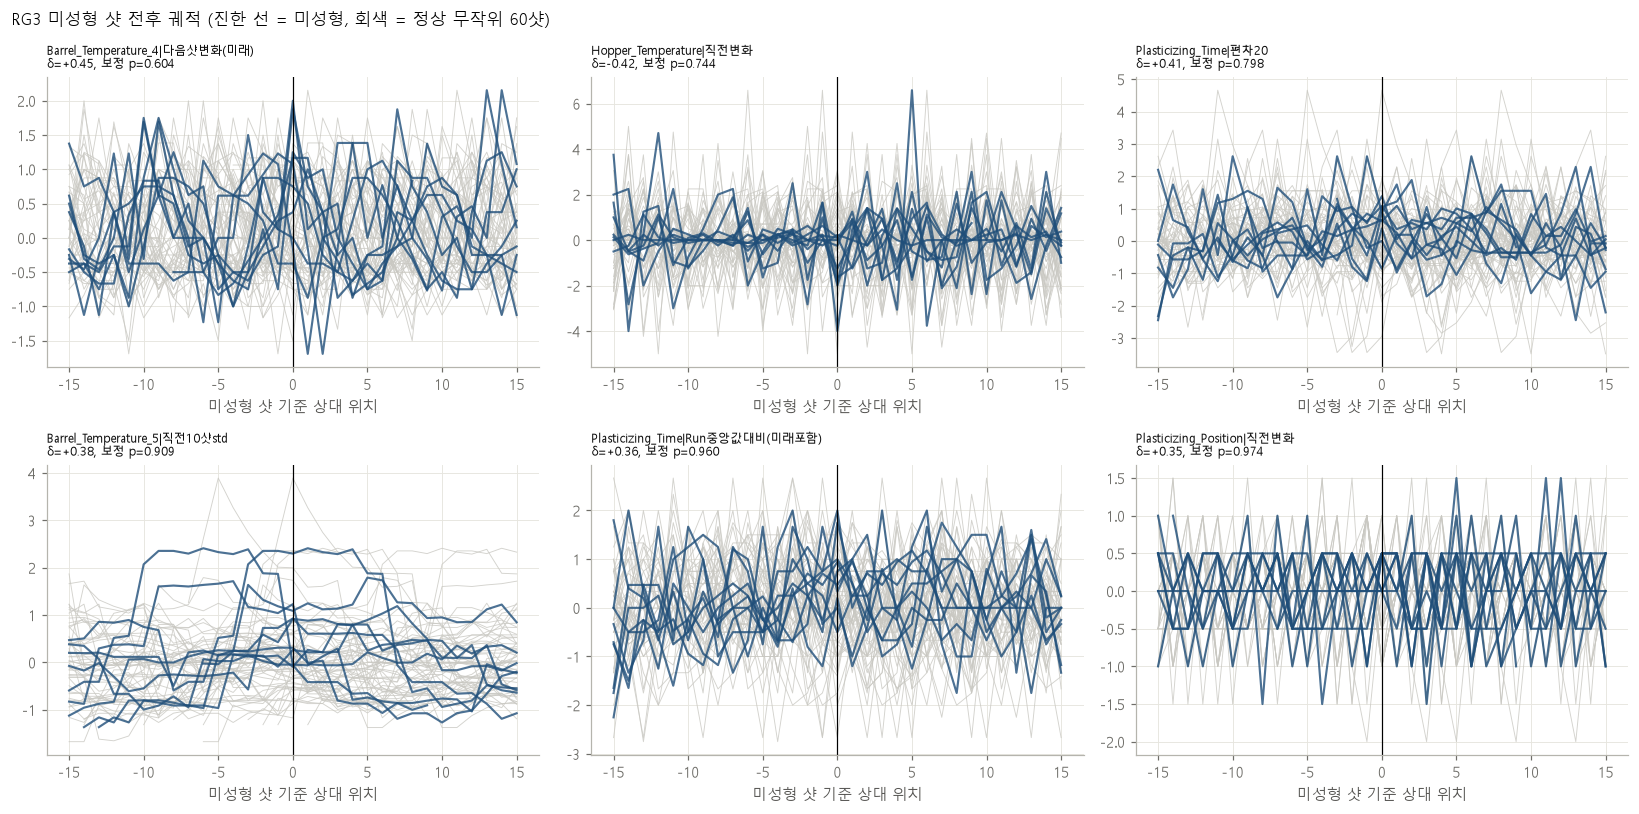

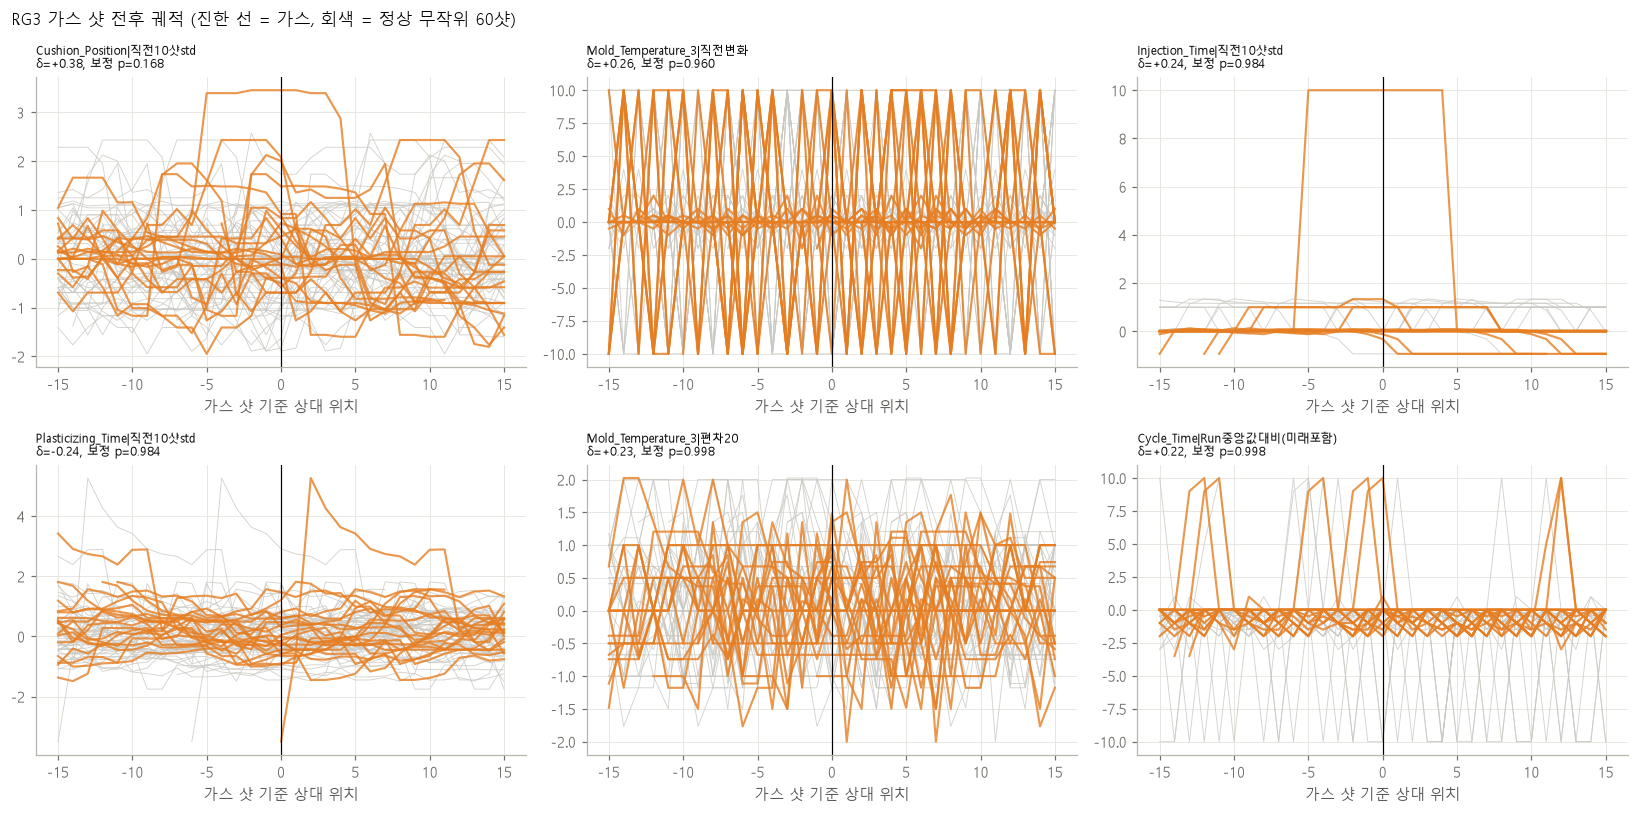

In [6]:
Q.plot_windows(R, '미성형', save='./outputs/rg3_short_scan/short_windows.png')
Q.plot_windows(R, '가스', save='./outputs/rg3_short_scan/gas_windows.png')

## 5. 시차 스캔 — 라벨이 몇 샷 어긋났을 가능성

In [7]:
display(R['lag'].round(3))
print(R['lag_meta'])

,시차(샷),최대 |δ|,그 변수,최소 보정 p
0,-5,0.539,Max_Injection_Pressure|직전변화,0.729
1,-4,0.480,Max_Injection_Pressure|편차20,0.962
2,-3,0.429,Barrel_Temperature_4|편차20,0.998
3,-2,0.435,Barrel_Temperature_5|직전10샷std,0.998
4,-1,0.459,Barrel_Temperature_3|편차20,0.988
5,0,0.449,Barrel_Temperature_4|다음샷변화(미래),0.996
6,1,0.449,Barrel_Temperature_4|직전변화,0.996
7,2,0.399,흐름저항(사출압/속도)|다음샷변화(미래),1.000
8,3,0.453,맥락|직전간격(초),0.994
9,4,0.592,Barrel_Temperature_1|다음샷변화(미래),0.349


{'대상': '미성형', '비교군': 'matched', '미성형 샷': 10, '정상 샷': 152, '변수 수': 1617, '무작위 최대 |δ| 95% 지점': 0.6770065789473684, '관측 최대 |δ|': 0.6151315789473684, '보정 p<0.05 변수 수': 0}
